<a href="https://colab.research.google.com/github/genius1oak/ConvexML/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/genius1oak/ConvexML/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [1]:

!git clone --depth 1 https://github.com/genius1oak/ConvexML.git

import os

repo = "/content/ConvexML"

print("\n===== REPOSITORY AUDIT =====")

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d != ".git"]

    for file in files:
        print(os.path.relpath(
            os.path.join(root, file), repo
        ))


Cloning into 'ConvexML'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 91 (delta 11), reused 61 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (91/91), 1.95 MiB | 19.34 MiB/s, done.
Resolving deltas: 100% (11/11), done.

===== REPOSITORY AUDIT =====
.gitignore
README.md
GUIDE.md
CLAUDE.md
SETUP.md
LICENSE
requirements.txt
AGENTS.md
DATA_USE.md
data/raw/content_refresh_anonymized.csv
scripts/02_baseline_score.py
scripts/03_train_model.py
scripts/05_build_pdf_report.py
scripts/ml_utils.py
scripts/01_prepare_features.py
scripts/run_all.py
scripts/04_evaluate_and_export.py
work/capstone_report_template.md
work/README.md
work/notebooks/capstone.ipynb
work/notebooks/w07_action_playbook.ipynb
work/notebooks/w05_model.ipynb
work/notebooks/w06_validation_audit.ipynb
work/notebooks/w01_research_question.ipynb
work/notebooks/w04_baseline_score.ipynb
work/notebooks/w03_data_contract.i

In [2]:

from pathlib import Path

repo = Path("/content/ConvexML")

files_to_read = [
    "skills/README.md",
    "skills/querying-big-datasets/SKILL.md",
    "skills/flyrank/flyrank-data/SKILL.md"
]

for filename in files_to_read:
    path = repo / filename

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")



FILE: skills/README.md
# Skills — the router

This folder is a small library of **skills**: focused instruction files your AI assistant loads
one at a time. One skill per task keeps the assistant sharp — its context window is small, and
filling it with everything makes it worse at the one thing you need.

**How to use it (repo-reading agents — Claude Code, Cursor, Codex):** they find this file
automatically via `AGENTS.md` / `CLAUDE.md`. Just tell your assistant which task you're doing.

**Using a chat-only assistant (ChatGPT / Gemini in a browser)?** Open the skill file on GitHub,
copy its whole content, and paste it into your chat before asking for help. That's it.

## The table — find your task, load ONE skill

| Your task | Load this skill | Also load for data work |
|---|---|---|
| Any task — how to work with your assistant at all | `directing-your-ai-assistant/SKILL.md` | — |
| Pick a lane, frame your question (ML-02, ML-03) | `framing-ml-problems/SKILL.md` | `flyrank/flyrank-da

In [3]:

from pathlib import Path
import pandas as pd
import re

repo = Path("/content/ConvexML")
csv_path = repo / "data/raw/content_refresh_anonymized.csv"

# 1. Read the data dictionary
dictionary_path = repo / "docs/data-dictionary.md"

print("=" * 70)
print("DATA DICTIONARY")
print("=" * 70)
print(dictionary_path.read_text(encoding="utf-8"))

# 2. Load the starter dataset
df = pd.read_csv(csv_path)

print("\n" + "=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("File size (MB):", round(csv_path.stat().st_size / (1024 ** 2), 2))

# 3. Column names and data types
print("\n" + "=" * 70)
print("COLUMN NAMES AND DATA TYPES")
print("=" * 70)
print(df.dtypes.to_string())

# 4. Missing values
print("\n" + "=" * 70)
print("MISSING VALUES (%)")
print("=" * 70)
print((df.isna().mean() * 100).round(2).to_string())

# 5. Potential date columns
print("\n" + "=" * 70)
print("DATE COLUMN CHECK")
print("=" * 70)

date_cols = [
    col for col in df.columns
    if re.search(r"date|day|time|week|month", col, re.I)
]

for col in date_cols:
    parsed = pd.to_datetime(df[col], errors="coerce")
    if parsed.notna().any():
        print(
            col,
            "| earliest:", parsed.min(),
            "| latest:", parsed.max()
        )

# 6. Potential target/label columns
print("\n" + "=" * 70)
print("POTENTIAL LABEL COLUMNS")
print("=" * 70)

label_cols = [
    col for col in df.columns
    if re.search(r"label|target|declin|refresh|action", col, re.I)
]

print(label_cols)

# 7. Duplicate check
print("\n" + "=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)
print("Fully duplicated rows:", df.duplicated().sum())

print("\nDataset inspection complete.")


DATA DICTIONARY
# Data Dictionary — `content_refresh_anonymized.csv`

One row per content item (page): **30,000 rows × 44 columns**, covering **32 pseudonymized
clients**. All metrics are aggregated over a trailing 90-day window ending at export time.
Keep this file open while you work.

## Read this first — the three rules that prevent 90% of mistakes

1. **Rate columns are ×100 percentages.** `ctr = 0.76` means **0.76%**, not 76%. Applies to
   `ctr`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, `trend_pct`.
2. **The label comes from `trend_direction`.** The pipeline defines
   `is_declining_label = (trend_direction == "down")`, so `trend_direction` and `trend_pct`
   must **never** be model features — that's the leakage notebook 02 demonstrates.
3. **IDs are for grouping only.** `content_id` / `client_id` are pseudonyms: use them for
   joins and grouped train/test splits, never as features.

## Identifiers

| Column | Type | Meaning | Notes |
|---|---|---|---|
| `content_id`

In [4]:

from pathlib import Path

repo = Path("/content/ConvexML")

files_to_inspect = [
    "DATA_USE.md",
    "work/README.md",
    "scripts/ml_utils.py",
    "scripts/01_prepare_features.py",
    "scripts/02_baseline_score.py",
    "scripts/03_train_model.py",
    "scripts/04_evaluate_and_export.py",
    "scripts/run_all.py",
]

for filename in files_to_inspect:
    path = repo / filename

    print("\n" + "=" * 80)
    print("FILE:", filename)
    print("=" * 80)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")



FILE: DATA_USE.md
# Data Use & Public-Safety Rules

The one dataset that ships with this repo is:

```text
data/raw/content_refresh_anonymized.csv
```

It is a small, **anonymized** slice of FlyRank content-performance data — one row per
pseudonymized content item, with observed search/engagement metrics, content metadata,
age/freshness fields, and derived comparison windows.

## What has already been removed

The starter export contains **no**:

- client names
- domains
- URLs
- page titles
- keywords or raw search queries
- product-rule flags used as composite scores you should trust blindly

Only hashed `content_id` / `client_id` labels plus numeric and categorical metrics remain.

Rate columns (`ctr`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, `trend_pct`) are
percentages on a 0–100 scale: `ctr = 0.76` means 0.76%, not 76%.

The hashed IDs are pseudonyms derived from FlyRank-internal database identifiers. They
contain no public information, but treat them as pseudonymous,

## 1. Question

*The research question and the decision it supports.*


## Research Question

Which content items show signals associated with declining search visibility, and how can these signals be used to prioritize content for review and potential refresh?

## Decision Supported

This research supports SEO and content teams in identifying and prioritizing content items that may require further investigation or refreshing.

The analysis will produce a ranked content review queue based on measurable search-performance signals. The ranking is intended to support human decision-making, not replace editorial judgment.

## Research Objective

To evaluate whether a reproducible scoring approach and machine learning models can help identify content items associated with declining search visibility, and compare their performance against a simple baseline.

## Scope

This is a decision-support study using anonymized FlyRank search-performance data. It does not attempt to prove Google's ranking algorithm or establish that refreshing content directly causes improved search performance.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*


## Dataset Description

This study uses the anonymized FlyRank ML Internship starter dataset, containing 30,000 content-item records and 44 columns.

Each row represents a pseudonymized content item with aggregated search-performance, engagement, content-characteristic, and historical performance metrics.

## Data Source

- Dataset: FlyRank ML Internship starter dataset
- File: `content_refresh_anonymized.csv`
- Records: 30,000
- Features and fields: 44
- Client coverage: 32 pseudonymized clients

## Data Privacy

The dataset contains anonymized identifiers. Client identifiers are used only where necessary for grouping and validation. No client names, website domains, page URLs, private search queries, or credentials will be included in the published research.

## Data Limitations

The starter dataset does not contain actual report dates. Its performance metrics are aggregated over defined historical windows.

The analysis will therefore distinguish between historical associations and genuine future prediction. No claim of prospective prediction will be made unless an approved time-based dataset supports it.

## Exclusions

- Client identifiers will not be used as model features.
- Direct target-derived fields, including `trend_pct` and `trend_direction`, will not be used as predictive features.
- Records and fields that could expose private client information will not be published.
- Additional warehouse data will only be used if formally approved.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*


## Research Design

The starter dataset supports a retrospective, cross-sectional classification study. The target is whether a content item is labelled as declining in the observed comparison period.

The target is defined as:

- 1: `trend_direction == "down"`
- 0: All other trend categories

## Feature Selection

The initial model will use content and keyword characteristics, including content type, search intent, keyword competition, search volume, content length, content age, and time since last update.

Performance metrics that overlap the target calculation will be excluded. These include the 30-day comparison metrics, 90-day performance totals, CTR, average position, engagement rate, scroll rate, AI traffic percentage, `trend_pct`, and `trend_direction`.

Pseudonymized content and client identifiers will not be used as model features.


## Validation Design

Evaluation will use a client-grouped holdout so that records belonging to a client do not appear in both training and testing sets.

The models will be compared with an oldest-content-first baseline, which ranks records by the number of days since their last update. Records with longer periods since their last update receive higher review priority. All approaches will be evaluated on the same held-out test records.


## Interpretation

Results will be interpreted as retrospective associations and decision-support signals. They will not be presented as evidence of future predictive performance or as proof that content refreshing causes improved search visibility.


In [9]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Ensure target and grouping variables are ready
y = df["trend_direction"].eq("down").astype(int)
groups = df["client_id"]

print("Overall target distribution:")
print(y.value_counts())
print("\nOverall decline rate:", round(y.mean(), 4))

# Try grouped splits, keeping each client entirely in one partition
splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=42
)

valid_split = None

for train_idx, test_idx in splitter.split(df, y, groups):
    train_classes = y.iloc[train_idx].nunique()
    test_classes = y.iloc[test_idx].nunique()

    if train_classes == 2 and test_classes == 2:
        valid_split = (train_idx, test_idx)
        break

if valid_split is None:
    print("\nNo valid grouped split found in these attempts.")
else:
    train_idx, test_idx = valid_split

    train_clients = set(groups.iloc[train_idx])
    test_clients = set(groups.iloc[test_idx])

    print("\nVALID GROUPED SPLIT FOUND")
    print("Training records:", len(train_idx))
    print("Testing records:", len(test_idx))
    print("Training clients:", len(train_clients))
    print("Testing clients:", len(test_clients))
    print("Overlapping clients:", len(train_clients & test_clients))
    print("Training decline rate:", round(y.iloc[train_idx].mean(), 4))
    print("Testing decline rate:", round(y.iloc[test_idx].mean(), 4))
    print("Training classes:", sorted(y.iloc[train_idx].unique()))
    print("Testing classes:", sorted(y.iloc[test_idx].unique()))


Overall target distribution:
trend_direction
1    16262
0    13738
Name: count, dtype: int64

Overall decline rate: 0.5421

VALID GROUPED SPLIT FOUND
Training records: 23837
Testing records: 6163
Training clients: 25
Testing clients: 7
Overlapping clients: 0
Training decline rate: 0.5501
Testing decline rate: 0.511
Training classes: [np.int64(0), np.int64(1)]
Testing classes: [np.int64(0), np.int64(1)]


In [10]:

# Define approved model features

numeric_features = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "content_age_days",
    "days_since_last_update"
]

categorical_features = [
    "content_type",
    "main_intent",
    "competition_level"
]

feature_columns = numeric_features + categorical_features

# Create modelling dataset
X = df[feature_columns].copy()
y = df["trend_direction"].eq("down").astype(int)

# Verify feature selection
print("NUMERIC FEATURES:", len(numeric_features))
print(numeric_features)

print("\nCATEGORICAL FEATURES:", len(categorical_features))
print(categorical_features)

print("\nTOTAL MODEL FEATURES:", len(feature_columns))

print("\nFEATURE MATRIX SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nMISSING VALUES IN SELECTED FEATURES:")
display(X.isna().sum().to_frame("missing_count"))

# Confirm excluded leakage-sensitive fields
excluded_fields = [
    "trend_direction",
    "trend_pct",
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "impressions_last_30d",
    "impressions_prev_30d",
    "clicks_last_30d",
    "clicks_prev_30d",
    "sessions_last_30d",
    "sessions_prev_30d",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "ai_traffic_pct",
    "content_id",
    "client_id"
]

print("\nLEAKAGE-SENSITIVE FIELDS EXCLUDED:")
print(excluded_fields)

assert not set(feature_columns).intersection(excluded_fields)
print("\nFeature exclusion check passed.")


NUMERIC FEATURES: 7
['search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'content_age_days', 'days_since_last_update']

CATEGORICAL FEATURES: 3
['content_type', 'main_intent', 'competition_level']

TOTAL MODEL FEATURES: 10

FEATURE MATRIX SHAPE: (30000, 10)
TARGET SHAPE: (30000,)

MISSING VALUES IN SELECTED FEATURES:


,missing_count
search_volume,2468
competition,2468
cpc,2468
word_count,7699
char_count,7699
content_age_days,0
days_since_last_update,0
content_type,0
main_intent,2374
competition_level,2610



LEAKAGE-SENSITIVE FIELDS EXCLUDED:
['trend_direction', 'trend_pct', 'impressions_90d', 'clicks_90d', 'sessions_90d', 'impressions_last_30d', 'impressions_prev_30d', 'clicks_last_30d', 'clicks_prev_30d', 'sessions_last_30d', 'sessions_prev_30d', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'content_id', 'client_id']

Feature exclusion check passed.


In [7]:

import pandas as pd
from pathlib import Path

# Locate the starter dataset
possible_paths = [
    Path("data/raw/content_refresh_anonymized.csv"),
    Path("../data/raw/content_refresh_anonymized.csv"),
    Path("/content/ConvexML/data/raw/content_refresh_anonymized.csv")
]

data_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Please check where you cloned ConvexML in Colab."
    )

# Load dataset
df = pd.read_csv(data_path)

print("DATASET OVERVIEW")
print("-" * 40)
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nTarget distribution:")
if "trend_direction" in df.columns:
    print(df["trend_direction"].value_counts(dropna=False))
else:
    print("trend_direction column not found.")


DATASET OVERVIEW
----------------------------------------
Shape: (30000, 44)

Column names:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

First five records:


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7



Target distribution:
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152
Name: count, dtype: int64


In [8]:

# 1. Missing values
print("MISSING VALUES")
missing = (
    df.isna().sum()
    .to_frame("missing_count")
)
missing["missing_pct"] = (
    missing["missing_count"] / len(df) * 100
)
display(
    missing[missing["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

# 2. Client distribution
print("\nCLIENT DISTRIBUTION")
print("Unique clients:", df["client_id"].nunique())
display(
    df["client_id"].value_counts().describe()
)

# 3. Target distribution by client
print("\nDECLINE RATE BY CLIENT")
df["is_declining"] = (
    df["trend_direction"].eq("down").astype(int)
)

client_summary = (
    df.groupby("client_id")
    .agg(
        records=("content_id", "count"),
        declining_records=("is_declining", "sum"),
        decline_rate=("is_declining", "mean")
    )
    .sort_values("decline_rate", ascending=False)
)

display(client_summary)

# 4. Check previous-period metrics
print("\nPREVIOUS 30-DAY METRICS")
display(
    df[
        [
            "impressions_prev_30d",
            "clicks_prev_30d",
            "sessions_prev_30d"
        ]
    ].describe()
)


MISSING VALUES


,missing_count,missing_pct
provider_used,21438,71.460000
word_count_tier,7699,25.663333
char_count,7699,25.663333
word_count,7699,25.663333
char_count_tier,7699,25.663333
model_used,5733,19.110000
trend_pct,3388,11.293333
competition_level,2610,8.700000
search_volume,2468,8.226667
competition,2468,8.226667



CLIENT DISTRIBUTION
Unique clients: 32


,count
count,32.000000
mean,937.500000
std,1376.387113
min,3.000000
25%,110.250000
50%,567.000000
75%,1058.750000
max,7008.000000



DECLINE RATE BY CLIENT


,records,declining_records,decline_rate
client_id,,,
client_7f2253d7e2,1043,977,0.936721
client_3fdba35f04,2267,1901,0.838553
client_9400f1b21c,158,121,0.765823
client_bdd2d3af3a,44,33,0.750000
client_349c41201b,763,526,0.689384
client_8722616204,578,387,0.669550
client_a88a7902cb,1171,782,0.667805
client_6208ef0f77,3681,2370,0.643847
client_98a3ab7c34,118,73,0.618644



PREVIOUS 30-DAY METRICS


,impressions_prev_30d,clicks_prev_30d,sessions_prev_30d
count,30000.000000,30000.000000,30000.000000
mean,1783.078500,5.435100,10.283000
std,6150.429511,28.358673,42.578003
min,0.000000,0.000000,0.000000
25%,19.000000,0.000000,1.000000
50%,210.000000,0.000000,2.000000
75%,1143.000000,2.000000,7.000000
max,218786.000000,1627.000000,4247.000000


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


## Model Evaluation Results

All three approaches were evaluated on the same held-out test set of 6,163 records from seven clients. No client appeared in both the training and testing partitions.

The test-set decline rate was 51.10%.

Logistic Regression achieved the highest Average Precision (0.5290) and ROC-AUC (0.5330), outperforming the oldest-content baseline on these two metrics.

However, the oldest-content baseline achieved higher Precision@20 (0.65) and Precision@50 (0.50) than either machine learning model.

Random Forest did not outperform Logistic Regression on the reported metrics.

These findings suggest that Logistic Regression provides a modest improvement in overall ranking discrimination, while the simple freshness-based baseline remains competitive for the highest-ranked items.

The results are retrospective associations within the starter dataset. They do not demonstrate future predictive performance or establish that refreshing content causes improved search visibility.


In [12]:

# Client-level evaluation diagnostics
test_diagnostics = df.iloc[test_idx][
    ["client_id"]
].copy()

test_diagnostics["actual_decline"] = y_test.to_numpy()
test_diagnostics["logistic_score"] = logistic_scores
test_diagnostics["forest_score"] = forest_scores
test_diagnostics["freshness_score"] = age_scores

client_results = (
    test_diagnostics.groupby("client_id")
    .agg(
        test_records=("actual_decline", "size"),
        decline_rate=("actual_decline", "mean"),
        logistic_avg_score=("logistic_score", "mean"),
        forest_avg_score=("forest_score", "mean")
    )
    .sort_values("test_records", ascending=False)
)

print("TEST SET DISTRIBUTION ACROSS HELD-OUT CLIENTS")
display(client_results.round(4))

print("\nTEST CLIENT COUNT:", len(client_results))
print("SMALLEST CLIENT TEST SET:", client_results["test_records"].min())
print("LARGEST CLIENT TEST SET:", client_results["test_records"].max())


TEST SET DISTRIBUTION ACROSS HELD-OUT CLIENTS


,test_records,decline_rate,logistic_avg_score,forest_avg_score
client_id,,,,
client_4e07408562,2294,0.4935,0.3999,0.4446
client_f369cb89fc,1796,0.6013,0.5778,0.5963
client_8527a891e2,1194,0.4372,0.5691,0.6210
client_e629fa6598,720,0.4556,0.3233,0.3671
client_434c9b5ae5,87,0.5172,0.6136,0.5728
client_bdd2d3af3a,44,0.7500,0.6099,0.6056
client_8b940be7fb,28,0.3214,0.6188,0.5951



TEST CLIENT COUNT: 7
SMALLEST CLIENT TEST SET: 28
LARGEST CLIENT TEST SET: 2294


In [13]:

from sklearn.metrics import average_precision_score, roc_auc_score

client_metric_rows = []

for client_id, group in test_diagnostics.groupby("client_id"):

    actual = group["actual_decline"].to_numpy()

    row = {
        "client_group": "held_out_group",
        "records": len(group),
        "decline_rate": actual.mean()
    }

    for model_name, score_column in [
        ("Baseline", "freshness_score"),
        ("Logistic", "logistic_score"),
        ("Random Forest", "forest_score")
    ]:
        scores = group[score_column].to_numpy()

        row[f"{model_name}_AP"] = average_precision_score(
            actual, scores
        )

        # ROC-AUC requires both target classes
        if len(np.unique(actual)) == 2:
            row[f"{model_name}_AUC"] = roc_auc_score(
                actual, scores
            )
        else:
            row[f"{model_name}_AUC"] = np.nan

    client_metric_rows.append(row)

client_metrics = pd.DataFrame(client_metric_rows)

print("PER-CLIENT MODEL PERFORMANCE")
display(client_metrics.round(4))

print("\nUNWEIGHTED MEAN AVERAGE PRECISION")
display(
    client_metrics[
        ["Baseline_AP", "Logistic_AP", "Random Forest_AP"]
    ].mean().to_frame("mean_average_precision").round(4)
)


PER-CLIENT MODEL PERFORMANCE


,client_group,records,decline_rate,Baseline_AP,Baseline_AUC,Logistic_AP,Logistic_AUC,Random Forest_AP,Random Forest_AUC
0,held_out_group,87,0.5172,0.5370,0.4873,0.5571,0.5079,0.5609,0.5725
1,held_out_group,2294,0.4935,0.4610,0.4028,0.5139,0.5253,0.4838,0.4568
2,held_out_group,1194,0.4372,0.4313,0.4899,0.4353,0.4970,0.4222,0.4737
3,held_out_group,28,0.3214,0.3913,0.6316,0.4681,0.6199,0.6130,0.5760
4,held_out_group,44,0.7500,0.7132,0.3457,0.7316,0.3416,0.6740,0.4077
5,held_out_group,720,0.4556,0.4622,0.5119,0.4779,0.5257,0.4295,0.4558
6,held_out_group,1796,0.6013,0.6238,0.5444,0.5983,0.4829,0.6354,0.5376



UNWEIGHTED MEAN AVERAGE PRECISION


,mean_average_precision
Baseline_AP,0.5171
Logistic_AP,0.5403
Random Forest_AP,0.5455


In [11]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Reuse the validated client-grouped split
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Preprocessing: fit only on training data
numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model 2: Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train models
print("Training Logistic Regression...")
logistic_model.fit(X_train, y_train)

print("Training Random Forest...")
random_forest_model.fit(X_train, y_train)

# Obtain decline scores on the same held-out test records
logistic_scores = logistic_model.predict_proba(X_test)[:, 1]
forest_scores = random_forest_model.predict_proba(X_test)[:, 1]

# Simple ranking baseline: oldest content first
age_scores = X_test["days_since_last_update"].fillna(0).to_numpy()

# Evaluate ranking and classification
def evaluate_model(name, scores, y_true):
    order = np.argsort(-np.asarray(scores))
    ranked_labels = np.asarray(y_true)[order]

    result = {
        "Approach": name,
        "Average Precision": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "Precision@20": ranked_labels[:20].mean(),
        "Precision@50": ranked_labels[:50].mean(),
        "Precision@100": ranked_labels[:100].mean()
    }

    return result

results = pd.DataFrame([
    evaluate_model("Oldest-content baseline", age_scores, y_test),
    evaluate_model("Logistic Regression", logistic_scores, y_test),
    evaluate_model("Random Forest", forest_scores, y_test)
])

print("\nMODEL COMPARISON — HELD-OUT CLIENTS")
display(results.round(4))

# Reference decline rate
print("\nTEST SET DECLINE RATE:", round(y_test.mean(), 4))
print("This is the random-ranking reference for Precision@K.")

# Confirm evaluation integrity
print("\nTRAINING CLIENTS:", len(set(groups.iloc[train_idx])))
print("TEST CLIENTS:", len(set(groups.iloc[test_idx])))
print(
    "CLIENT OVERLAP:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)


Training Logistic Regression...
Training Random Forest...

MODEL COMPARISON — HELD-OUT CLIENTS


,Approach,Average Precision,ROC-AUC,Precision@20,Precision@50,Precision@100
0,Oldest-content baseline,0.4864,0.4409,0.65,0.50,0.51
1,Logistic Regression,0.5290,0.5330,0.50,0.48,0.45
2,Random Forest,0.5172,0.5166,0.40,0.44,0.45



TEST SET DECLINE RATE: 0.511
This is the random-ranking reference for Precision@K.

TRAINING CLIENTS: 25
TEST CLIENTS: 7
CLIENT OVERLAP: 0


## 5. Limitations

*What this work cannot claim.*


## Limitations

### 1. Retrospective Target

The target variable is derived from historical performance comparisons. This study evaluates associations with observed decline labels rather than predicting future search visibility changes.

### 2. Limited Historical Context

The starter dataset contains aggregated performance windows rather than dated daily observations. It does not support a rigorous chronological training and testing design.

### 3. Client Imbalance

The dataset contains 32 pseudonymized clients with highly uneven record counts. The held-out test set contains seven clients, and four contribute most of the test records.

### 4. Variation Across Clients

Model performance differs across held-out clients. Aggregate results may not represent performance for every client or website.

### 5. Missing Data

Several fields have substantial missingness, including provider information, content length, search volume, and keyword intent. Imputation may affect model behaviour.

### 6. Baseline Limitations

The oldest-content baseline is intentionally simple. Its performance does not establish that content age alone is a sufficient refresh decision rule.

### 7. No Causal Evidence

The study does not establish that updating or refreshing content causes improvements in search rankings, impressions, clicks, or traffic.

### 8. Generalisability

The findings are based on the anonymized starter dataset and should not automatically be generalised to other websites, industries, or search environments.

### Overall Interpretation

The models and baseline provide retrospective decision-support signals for prioritising content review. Their outputs require human assessment and further validation before operational deployment.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*


## Ranked Recommendations

The recommendation queue ranks content items according to their estimated association with the observed decline label.

The queue is intended to help content teams prioritise manual review, not to prescribe automatic content updates.

Each recommendation should be assessed against its search intent, content quality, relevance, accuracy, and available performance evidence.

Items with higher model scores should be treated as review candidates rather than confirmed refresh opportunities.


In [14]:

import numpy as np
import pandas as pd

# Rank held-out test records using Logistic Regression scores.
# These are review-priority scores, not calibrated probabilities.
review_queue = X_test.copy()
review_queue["decline_association_score"] = logistic_scores

review_queue = review_queue.sort_values(
    "decline_association_score",
    ascending=False
).copy()

review_queue["rank"] = np.arange(1, len(review_queue) + 1)
review_queue["rank_percentile"] = (
    review_queue["rank"] / len(review_queue)
)

review_queue["priority_tier"] = np.select(
    [
        review_queue["rank_percentile"] <= 0.10,
        review_queue["rank_percentile"] <= 0.30
    ],
    [
        "High priority",
        "Medium priority"
    ],
    default="Standard review"
)

# Summarise the queue without publishing individual content or client IDs.
queue_summary = (
    review_queue
    .groupby("priority_tier", observed=True)
    .agg(
        content_items=("rank", "count"),
        median_content_age_days=("content_age_days", "median"),
        median_days_since_update=("days_since_last_update", "median"),
        median_search_volume=("search_volume", "median"),
        median_review_score=("decline_association_score", "median")
    )
    .reindex(["High priority", "Medium priority", "Standard review"])
    .reset_index()
)

print("Ranked review queue summary (held-out test set)")
display(queue_summary.round(3))


Ranked review queue summary (held-out test set)


,priority_tier,content_items,median_content_age_days,median_days_since_update,median_search_volume,median_review_score
0,High priority,616,105.0,20.0,10.0,0.625
1,Medium priority,1232,126.0,20.0,0.0,0.594
2,Standard review,4315,390.0,20.0,20.0,0.417



### Review Queue Interpretation

The Logistic Regression model was used to rank the 6,163 records in the held-out test set by their decline-association scores.

The resulting queue assigns:
- 616 records (10%) to high-priority review.
- 1,232 records (20%) to medium-priority review.
- 4,315 records (70%) to standard review.

The high-priority group has the highest median model score (0.625), compared with 0.594 for the medium-priority group and 0.417 for the standard-review group.

The median content age differs across the groups. Interestingly, the high-priority group has a median age of 105 days, while the standard-review group has a median age of 390 days. This indicates that the model's ranking is not simply an oldest-content-first ranking.

These tiers are intended to guide further investigation. They do not establish that individual records are declining, nor do they demonstrate that refreshing content will improve search performance. Editorial teams should verify each candidate before taking action.


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

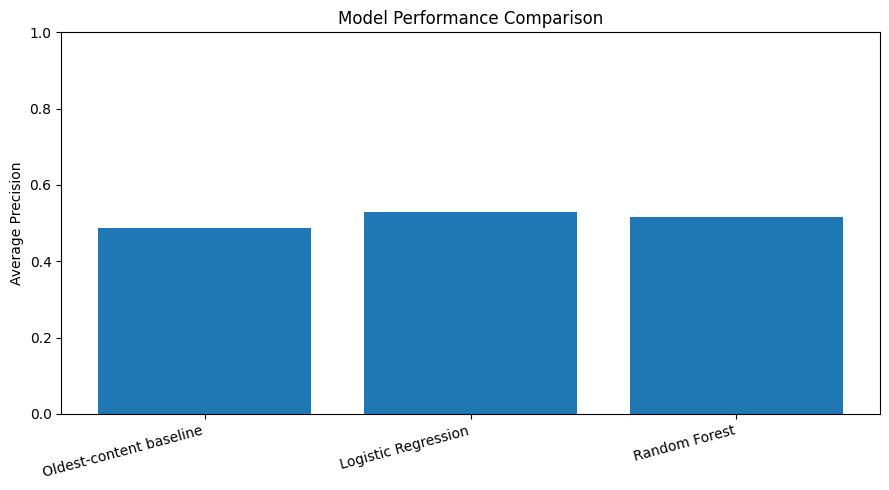

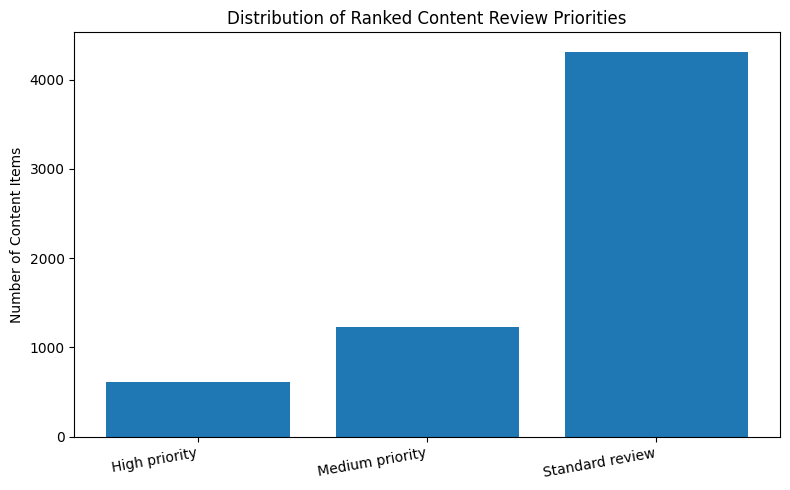

In [15]:

import matplotlib.pyplot as plt

# 1. Compare model performance using Average Precision
performance = pd.DataFrame({
    "Approach": [
        "Oldest-content baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Average Precision": [
        0.4864,
        0.5290,
        0.5172
    ]
})

plt.figure(figsize=(9, 5))
plt.bar(performance["Approach"], performance["Average Precision"])
plt.title("Model Performance Comparison")
plt.ylabel("Average Precision")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# 2. Show the distribution of review priority tiers
tier_order = ["High priority", "Medium priority", "Standard review"]

tier_counts = (
    review_queue["priority_tier"]
    .value_counts()
    .reindex(tier_order)
)

plt.figure(figsize=(8, 5))
plt.bar(tier_counts.index, tier_counts.values)
plt.title("Distribution of Ranked Content Review Priorities")
plt.ylabel("Number of Content Items")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()



## 8. Reproducibility

### Environment and Tools
The analysis was conducted in Python using Google Colab and the following libraries:
- pandas and NumPy for data handling.
- scikit-learn for preprocessing, model development, and evaluation.
- Matplotlib for visualisation.

### Dataset
The study uses the anonymized FlyRank ML Internship starter dataset (`content_refresh_anonymized.csv`), containing 30,000 records and 44 columns.

### Data Preparation
The target variable was derived from `trend_direction`, with records labelled `down` assigned 1 and all other categories assigned 0.

Target-derived fields and overlapping search-performance metrics were excluded from the predictors to reduce direct target leakage. Client identifiers were used for grouped validation but excluded from model features.

Missing numerical values were imputed using training-set medians, while missing categorical values were imputed using the most frequent training-set category.

### Validation
A reproducible, client-grouped holdout split was created using `GroupShuffleSplit` with random seed 42. The training set contained 25 clients, while the held-out test set contained 7 different clients. No clients overlapped between the two sets.

### Models and Evaluation
The study compared:
1. An oldest-content-first baseline.
2. Logistic Regression.
3. Random Forest.

All approaches were evaluated on the same held-out test set using Average Precision, ROC-AUC, and Precision at 20, 50, and 100.

### Reproducibility Materials
The notebook contains the data preparation, feature selection, validation, model training, evaluation, ranked review queue, and visualisation steps.

The notebook and supporting research materials should be committed to the project repository. The published paper should contain only anonymized, public-safe summaries and should not expose individual client or content identifiers.



## 9. Acknowledgments & Data Credit

This research was completed as part of the FlyRank ML Internship Capstone.

The analysis uses the anonymized FlyRank ML Internship starter dataset. The author acknowledges FlyRank for providing the dataset and the opportunity to conduct this research.

Built on the [FlyRank ML Internship dataset](https://flyrank.ai).



# ML-12: Capstone Closing Deliverables

## 10. Five-Minute Demo Outline

**0:00–0:45 | Research Problem**
- Introduce the challenge of identifying content associated with declining search visibility.
- Explain the decision the analysis is designed to support.

**0:45–1:30 | Dataset and Preparation**
- Introduce the anonymized FlyRank starter dataset.
- Explain the target definition, selected features, missing-value treatment, and excluded leakage-prone fields.

**1:30–2:30 | Methodology**
- Explain the client-grouped train/test split.
- Introduce the oldest-content baseline, Logistic Regression, and Random Forest.
- Explain why client identifiers and overlapping performance metrics were excluded from model features.

**2:30–3:30 | Results**
- Present the model performance comparison.
- Highlight Logistic Regression's Average Precision of 0.5290 and ROC-AUC of 0.5330.
- Explain that the baseline performed better on the reported Precision@K measures.

**3:30–4:30 | Ranked Recommendations**
- Demonstrate the three review-priority tiers.
- Explain how the ranked queue can support human review.
- Emphasise that the scores are prioritisation signals, not confirmed predictions of future decline.

**4:30–5:00 | Limitations and Conclusion**
- Highlight the retrospective nature of the study and variation across clients.
- Explain the potential value of further validation with approved time-based data.
- Close with the intended decision-support application.

## 11. Social Post Cut

I completed my Google Search Ranking & Discoverability Capstone as part of the FlyRank ML Internship.

The project explored how machine learning and structured analysis can help identify content associated with declining search visibility and support more informed content-review priorities.

Using an anonymized dataset, I compared an oldest-content baseline, Logistic Regression, and Random Forest, evaluated their performance using client-grouped validation, and developed a ranked content-review queue.

One key takeaway was that model performance depends on the evaluation metric and validation design. The results also reinforced the importance of leakage prevention, honest interpretation, and human oversight.

This project strengthened my practical experience in data preparation, machine learning, model evaluation, and translating analytical results into actionable recommendations.

Built on the FlyRank ML Internship dataset: https://flyrank.ai

## 12. Three-Sentence Employer Summary

Developed a reproducible machine-learning analysis using an anonymized dataset of 30,000 content records to examine signals associated with declining search visibility. Compared an oldest-content baseline, Logistic Regression, and Random Forest using client-grouped validation, then translated the results into a ranked content-review framework. The project demonstrates practical skills in Python, data preparation, leakage-aware feature selection, model evaluation, analytical communication, and evidence-based decision support.


In [16]:
import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Matplotlib: 3.10.0


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
